# Materi 9: Aplikasi Crawler + PageRank

Materi ini beda dari materi 8. Kalau materi 8 masih ngomongin teori sentralitas dan PageRank, di sini yang dibahas kode aplikasinya, dari crawler sampai tampilan Streamlit-nya.

Bahan project-nya folder `aplikasi-crawler-pagerank`. Aplikasinya crawling website kampus, ngubah hasil crawl jadi graph berarah, ngitung PageRank tiap halaman, terus nampilin semuanya di lima tab. Intinya biar teori di materi 7 dan 8 ada wujudnya.

Formatnya ngikutin materi 6: tiap bagian ada lokasi kodenya, potongan kodenya, penjelasan, terus pembuktian dari eksekusi asli. Jadi kalimat kayak "crawler nyimpen busur" bukan cuma klaim, tapi ada output yang nunjukin.

Link aplikasi: belum di-deploy waktu catatan ini ditulis. Nanti diisi setelah naik ke Streamlit Community Cloud.

## 1. Struktur aplikasi

Logika aplikasinya sengaja dipisah dari tampilan. Alasannya simpel: crawler yang sama harus bisa dipakai lewat browser buat demo, dan lewat terminal buat crawl besar. Kalau semua ditumpuk di `streamlit_app.py`, versi terminal harus ngimpor file Streamlit, dan itu ribet.

Isi foldernya begini. `app/crawler.py` ngurus pengambilan halaman dan ekstraksi tautan. `app/graph_analysis.py` ngubah hasil crawl jadi graph, ngitung PageRank, statistik, matriks adjacency, dan gambar statis. `app/graph_interaktif.py` bikin HTML graph yang bisa di-zoom dan di-hover. `app/streamlit_app.py` antarmukanya. `run_crawl.py` versi terminal buat crawl skala besar. Terus ada `output/` buat hasil crawl, `requirements.txt`, dan `README.md`.

Pembagian ini yang bikin `run_crawl.py` bisa nyimpen CSV dan GraphML tanpa perlu Streamlit nyala.

In [1]:
import sys
from pathlib import Path

AKAR = Path.cwd()
if not (AKAR / "aplikasi-crawler-pagerank").exists():
    AKAR = AKAR.parent
APP = AKAR / "aplikasi-crawler-pagerank"
sys.path.insert(0, str(APP))

print("Akar Webmining :", AKAR)
print("Folder aplikasi:", APP)
print("Folder ada     :", APP.exists())
print()
print("Isi folder aplikasi:")
for nama in [
    "app/__init__.py",
    "app/crawler.py",
    "app/graph_analysis.py",
    "app/graph_interaktif.py",
    "app/streamlit_app.py",
    "run_crawl.py",
    "requirements.txt",
    "README.md",
]:
    path = APP / nama
    status = "ADA" if path.exists() else "HILANG"
    ukuran = f"{path.stat().st_size / 1024:7.1f} KB" if path.exists() else ""
    print(f"  {nama:28s} {status:6s} {ukuran}")

Akar Webmining : D:\Kuliah\Semester 7\Pencarian & Penambangan Web\Webmining
Folder aplikasi: D:\Kuliah\Semester 7\Pencarian & Penambangan Web\Webmining\aplikasi-crawler-pagerank
Folder ada     : True

Isi folder aplikasi:
  app/__init__.py              ADA        0.0 KB
  app/crawler.py               ADA        5.5 KB
  app/graph_analysis.py        ADA        4.0 KB
  app/graph_interaktif.py      ADA        4.8 KB
  app/streamlit_app.py         ADA        8.3 KB
  run_crawl.py                 ADA        3.0 KB
  requirements.txt             ADA        0.1 KB
  README.md                    ADA        4.6 KB


Output di atas nunjukin file yang disebut tadi memang ada semua, lengkap sama ukurannya. Folder `app` juga punya `__init__.py`, jadi bisa diimpor sebagai package waktu `sys.path` diarahkan ke folder aplikasi.

### 2.1 Normalisasi URL

Lokasi kode: `aplikasi-crawler-pagerank/app/crawler.py`, baris 45-58.

In [ ]:
def normalize_url(url: str) -> str:
    """Rapikan URL: buang fragment, samakan huruf host, buang port default."""
    url, _ = urldefrag(url.strip())
    parsed = urlparse(url)
    scheme = parsed.scheme.lower()
    netloc = parsed.netloc.lower()
    if scheme == "http" and netloc.endswith(":80"):
        netloc = netloc[:-3]
    if scheme == "https" and netloc.endswith(":443"):
        netloc = netloc[:-4]
    path = parsed.path or "/"
    path = re.sub(r"/{2,}", "/", path)
    query = f"?{parsed.query}" if parsed.query else ""
    return f"{scheme}://{netloc}{path}{query}"

Penjelasan:

Fungsi ini ngerapihin URL sebelum dimasukin antrean. Fragment kayak `#kontak` dibuang, karna fragment cuma nunjuk bagian halaman, bukan halaman baru. Huruf host diseragamkan jadi kecil, port default 80 dan 443 dibuang, slash dobel dirapihin, dan path kosong diganti `/`.

Kenapa repot-repot? Karna satu halaman bisa muncul dalam beberapa bentuk URL. Kalau gak dinormalisasi, crawler bakal ngira itu halaman berbeda, antrean jadi penuh duplikat, dan graph-nya punya simpul palsu.

In [3]:
from app.crawler import normalize_url

contoh = [
    "HTTPS://WWW2.Trunojoyo.ac.id//profil/#kontak",
    "http://trunojoyo.ac.id:80/berita/?hal=2",
    "https://trunojoyo.ac.id:443",
    "https://www2.trunojoyo.ac.id/category/berita/#top",
]

for url in contoh:
    print(f"{url}\n  -> {normalize_url(url)}")

print()
print(
    "Dua bentuk dianggap sama:",
    normalize_url("https://www2.trunojoyo.ac.id/")
    == normalize_url("https://WWW2.Trunojoyo.ac.id:443/#beranda"),
)

HTTPS://WWW2.Trunojoyo.ac.id//profil/#kontak
  -> https://www2.trunojoyo.ac.id/profil/
http://trunojoyo.ac.id:80/berita/?hal=2
  -> http://trunojoyo.ac.id/berita/?hal=2
https://trunojoyo.ac.id:443
  -> https://trunojoyo.ac.id/
https://www2.trunojoyo.ac.id/category/berita/#top
  -> https://www2.trunojoyo.ac.id/category/berita/

Dua bentuk dianggap sama: True


Hasilnya kelihatan: fragment hilang, host jadi huruf kecil, port default dibuang, slash dobel jadi satu, dan path kosong jadi `/`. Baris terakhir `True` membuktikan dua URL yang beda tulisan tapi sama tujuan dianggap satu simpul, jadi gak dobel di antrean.

### 2.2 Ekstraksi tautan

Lokasi kode: `aplikasi-crawler-pagerank/app/crawler.py`, baris 77-101.

In [ ]:
def ambil_tautan(
    soup: BeautifulSoup, base_url: str, abaikan_navigasi: bool = False
) -> list[str]:
    """Ambil semua href di satu halaman, ubah jadi URL absolut, buang duplikat.

    Kalau abaikan_navigasi=True, tautan yang cuma ada di header, nav, footer,
    atau sidebar dibuang. Tautan kayak gitu biasanya menu yang nongol di semua
    halaman, jadi bikin graph jadi hampir lengkap dan PageRank semua seri.
    """
    hasil = []
    terlihat = set()
    for tag in soup.find_all("a", href=True):
        if abaikan_navigasi and tag.find_parent(["header", "nav", "footer", "aside"]):
            continue
        href = tag["href"].strip()
        if not href or href.startswith(("#", "mailto:", "tel:", "javascript:", "data:")):
            continue
        url = normalize_url(urljoin(base_url, href))
        if not bisa_dikunjungi(url):
            continue
        if url in terlihat:
            continue
        terlihat.add(url)
        hasil.append(url)
    return hasil

Penjelasan:

Fungsi ini nyisir semua tag `a` yang punya `href`. Tautan relatif diubah jadi absolut pakai `urljoin`, terus dinormalisasi. Yang cuma nunjuk ke diri sendiri kayak `#top`, atau pakai skema `mailto:`, `tel:`, `javascript:`, dan `data:` langsung dibuang. `bisa_dikunjungi` nyaring ekstensi yang jelas bukan halaman, misal PDF, gambar, video, CSS, dan JS.

Duplikat dibuang pakai set `terlihat`, karna satu halaman biasanya nge-link URL yang sama berkali-kali.

Bagian `abaikan_navigasi` itu tambahan yang muncul waktu ngerjain project. Kalau nyala, tautan yang berada di dalam `header`, `nav`, `footer`, atau `aside` dilewati. Alasannya ada di pembuktian di bawah.

In [5]:
import requests
from bs4 import BeautifulSoup

from app.crawler import USER_AGENT, ambil_tautan

respons = requests.get(
    "https://trunojoyo.ac.id",
    headers={"User-Agent": USER_AGENT},
    timeout=20,
    allow_redirects=True,
)
respons.raise_for_status()
soup = BeautifulSoup(respons.content, "lxml")

semua = ambil_tautan(soup, respons.url)
tanpa_menu = ambil_tautan(soup, respons.url, abaikan_navigasi=True)
hanya_menu = [url for url in semua if url not in set(tanpa_menu)]

print("Status HTTP          :", respons.status_code)
print("URL akhir            :", respons.url)
print("Tautan unik (semua)  :", len(semua))
print("Tautan unik (isi)    :", len(tanpa_menu))
print("Tautan cuma di menu  :", len(hanya_menu))
print()
print("Contoh tautan di isi halaman:")
for url in tanpa_menu[:3]:
    print("  ", url)
print("Contoh tautan yang cuma ada di menu:")
for url in hanya_menu[:3]:
    print("  ", url)

Status HTTP          : 200
URL akhir            : https://www2.trunojoyo.ac.id/
Tautan unik (semua)  : 71
Tautan unik (isi)    : 15
Tautan cuma di menu  : 56

Contoh tautan di isi halaman:
   https://youtu.be/gZY1hQlWZIU
   https://www2.trunojoyo.ac.id/category/headlines/
   https://www2.trunojoyo.ac.id/category/informasi/
Contoh tautan yang cuma ada di menu:
   https://www2.trunojoyo.ac.id/sejarahutm/
   https://www2.trunojoyo.ac.id/index.php/profil-singkat/
   https://www2.trunojoyo.ac.id/visimisi/


Dari output, homepage punya 71 tautan unik. Setelah menu dibuang tinggal 15, jadi 56 tautan memang cuma nempel di header dan footer. Contoh yang kebuang itu link profil, sejarah, dan visi misi yang nongol di semua halaman.

Kalau tautan menu ikut dihitung, semua halaman saling nyambung ke puluhan halaman menu yang sama. Graph jadi hampir lengkap, dan PageRank halaman menu seri semua. Makanya di aplikasi opsi ini nyala secara default.

### 2.3 Crawl BFS

Lokasi kode: `aplikasi-crawler-pagerank/app/crawler.py`, baris 104-178.

In [ ]:
def crawl(
    start_url: str,
    max_pages: int = 30,
    max_depth: int = 2,
    same_site_only: bool = True,
    delay: float = 0.2,
    timeout: int = 15,
    abaikan_navigasi: bool = False,
    on_progress=None,
) -> CrawlResult:
    """Crawl BFS dari start_url, catat semua busur halaman -> tautan.

    on_progress dipanggil tiap halaman selesai dengan (jumlah_halaman, url).
    """
    awal = normalize_url(start_url)
    mulai = time.time()

    sesi = requests.Session()
    sesi.headers.update({
        "User-Agent": USER_AGENT,
        "Accept-Language": "id-ID,id;q=0.9,en;q=0.8",
        "Accept": "text/html,application/xhtml+xml",
    })

    antre = deque([(awal, 0)])
    sudah_masuk = {awal}
    hasil = CrawlResult(start_url=awal)
    kunci_situs = None

    while antre and len(hasil.pages) < max_pages:
        url, kedalaman = antre.popleft()

        try:
            respon = sesi.get(url, timeout=timeout, allow_redirects=True)
            respon.raise_for_status()
        except requests.RequestException as error:
            hasil.errors.append({"url": url, "alasan": f"gagal diambil: {error}"})
            continue

        tipe = respon.headers.get("content-type", "").lower()
        if "html" not in tipe:
            hasil.errors.append({"url": url, "alasan": f"bukan HTML ({tipe or 'tanpa content-type'})"})
            continue

        url_akhir = normalize_url(respon.url)
        if kunci_situs is None:
            kunci_situs = site_key(url_akhir)

        soup = BeautifulSoup(respon.content, "lxml")
        judul = soup.title.get_text(" ", strip=True) if soup.title else ""
        tautan = ambil_tautan(soup, url_akhir, abaikan_navigasi=abaikan_navigasi)

        hasil.pages[url_akhir] = {
            "judul": judul,
            "kedalaman": kedalaman,
            "jumlah_tautan": len(tautan),
        }

        for target in tautan:
            if same_site_only and site_key(target) != kunci_situs:
                continue
            if target == url_akhir:
                continue
            hasil.edges.add((url_akhir, target))
            if target not in sudah_masuk and kedalaman + 1 <= max_depth:
                sudah_masuk.add(target)
                antre.append((target, kedalaman + 1))

        if delay > 0:
            time.sleep(delay)
        if on_progress is not None:
            on_progress(len(hasil.pages), url_akhir)

    hasil.duration = time.time() - mulai
    return hasil

Penjelasan:

Crawl-nya pakai BFS, kelihatan dari `deque` yang di-`popleft`, jadi halaman yang ditemukan lebih dulu dikunjungi lebih dulu. Antrean menyimpan pasangan URL dan kedalamannya.

Mulai dari URL awal, tiap halaman diambil pakai `requests.Session` biar koneksinya bisa dipakai ulang. Kalau request gagal atau content-type-nya bukan HTML, halaman dicatat di `errors` dan crawl lanjut ke antrean berikutnya. Halaman yang berhasil disimpan di `pages` bareng judul, kedalaman, dan jumlah tautannya.

Pasangan halaman asal dan tujuan dimasukin ke `edges`. Tapi target cuma dimasuki antrean kalau masih satu situs, belum pernah masuk, dan kedalamannya belum lewat `max_depth`. Loop berhenti kalau antrean habis atau jumlah halaman sudah mencapai `max_pages`.

Jadi `max_pages` itu batas atas, bukan target. Kalau antrean habis duluan, crawl berhenti dengan halaman lebih sedikit. Itu sebabnya hasil bisa 45 walaupun batasnya 100.

In [7]:
from collections import Counter

from app.crawler import crawl

hasil_uji = crawl(
    "https://trunojoyo.ac.id",
    max_pages=15,
    max_depth=2,
    delay=0.05,
    abaikan_navigasi=True,
)

sebaran = Counter(info["kedalaman"] for info in hasil_uji.pages.values())

print("Halaman berhasil :", hasil_uji.jumlah_halaman)
print("Busur tercatat   :", hasil_uji.jumlah_edge)
print("Gagal diambil    :", len(hasil_uji.errors))
print("Waktu crawl      :", round(hasil_uji.duration, 1), "detik")
print("Sebaran kedalaman:", dict(sorted(sebaran.items())))
print()
print("Contoh halaman yang gagal:")
for err in hasil_uji.errors[:3]:
    print("  ", err["url"])
    print("     alasan:", err["alasan"][:100])

Halaman berhasil : 15
Busur tercatat   : 221
Gagal diambil    : 1
Waktu crawl      : 3.3 detik
Sebaran kedalaman: {1: 4, 2: 11}

Contoh halaman yang gagal:
   https://www2.trunojoyo.ac.id/?page_id=3
     alasan: gagal diambil: 404 Client Error: Not Found for url: https://www2.trunojoyo.ac.id/?page_id=3


Output di atas nunjukin crawl berhenti tepat di 15 halaman, karna batas `max_pages`-nya memang 15. Batas itu cuma atap, bukan target: kalau antreannya habis duluan, crawl berhenti lebih awal.

Yang lebih menarik, busur yang tercatat 221, jauh lebih banyak dari 98 pasangan yang akhirnya masuk graph. Sisanya tautan ke halaman yang gak sempat dikunjungi, jadi ujungnya belum punya simpul.

Sebaran kedalamannya `{1: 4, 2: 11}`, gak ada angka 0. Itu bukan salah hitung, tapi efek redirect. URL awal `trunojoyo.ac.id` dialihkan ke `www2.trunojoyo.ac.id`, dan alamat hasil redirect itu jugak nongol sebagai tautan biasa di halaman lain. Jadi homepage kebuka dua kali, dan catatan kedalamannya ketimpa yang lebih dalam. Polanya tetap kelihatan: 4 halaman di kedalaman 1, sisanya di kedalaman 2.

Satu halaman yang gagal tetap kecatat alasannya, lengkap sama status 404-nya, dan itu gak bikin crawl berhenti.

## 3. Graph dan PageRank

### 3.1 Bangun graph

Lokasi kode: `aplikasi-crawler-pagerank/app/graph_analysis.py`, baris 10-20.

In [ ]:
def bangun_graph(hasil_crawl) -> nx.DiGraph:
    """Ubah hasil crawl jadi digraph yang cuma berisi halaman yang berhasil diambil."""
    graph = nx.DiGraph()
    for url, info in hasil_crawl.pages.items():
        graph.add_node(url, judul=info.get("judul", ""), kedalaman=info.get("kedalaman", 0))

    for sumber, target in hasil_crawl.edges:
        if sumber in graph and target in graph:
            graph.add_edge(sumber, target)

    return graph

Penjelasan:

Fungsi ini ngubah `CrawlResult` jadi `nx.DiGraph`. Semua halaman yang berhasil diambil jadi simpul, lengkap sama atribut judul dan kedalaman. Busur cuma ditambah kalau kedua ujungnya ada di daftar simpul.

Filter di baris terakhir penting. Hasil crawl nyatet tautan ke halaman yang belum tentu berhasil diambil, misal kena batas `max_pages` atau bukan HTML. Kalau semua busur dimasukin, graph bakal punya busur ke simpul hantu yang gak ada, dan PageRank bisa error atau ngasih hasil aneh.

In [9]:
from app.graph_analysis import bangun_graph

G_uji = bangun_graph(hasil_uji)

print("Simpul di graph          :", G_uji.number_of_nodes())
print("Busur di graph           :", G_uji.number_of_edges())
print("Busur tercatat saat crawl:", hasil_uji.jumlah_edge)
print("Busur dibuang            :", hasil_uji.jumlah_edge - G_uji.number_of_edges())

nyasar = [(a, b) for a, b in G_uji.edges if a not in G_uji or b not in G_uji]
print("Busur dengan ujung hilang:", len(nyasar))

Simpul di graph          : 15
Busur di graph           : 98
Busur tercatat saat crawl: 221
Busur dibuang            : 123
Busur dengan ujung hilang: 0


Output di atas nunjukin jumlah busur hasil crawl dibanding jumlah busur yang akhirnya masuk graph. Selisihnya itu busur yang ujungnya belum sempat dikunjungi, jadi memang harus dibuang. Pengecekan ujung busur menghasilkan nol, artinya gak ada busur nyasar.

### 3.2 PageRank

Rumus yang dipakai tetap rumus PageRank yang di materi 8:

$$PR(u) = \frac{1-d}{N} + d \sum_{v \in B(u)} \frac{PR(v)}{L(v)}$$

`d` faktor damping, `B(u)` himpunan halaman yang nge-link ke `u`, dan `L(v)` jumlah tautan keluar dari `v`.

Lokasi kode: `aplikasi-crawler-pagerank/app/graph_analysis.py`, baris 32-51.

In [ ]:
def peringkat_pagerank(graph: nx.DiGraph, alpha: float = 0.85) -> pd.DataFrame:
    """Hitung PageRank lalu balikin tabel terurut dari skor paling besar."""
    skor = nx.pagerank(graph, alpha=alpha) if graph.number_of_nodes() else {}

    baris = []
    for url in graph.nodes:
        baris.append({
            "url": url,
            "judul": graph.nodes[url].get("judul", ""),
            "pagerank": skor.get(url, 0.0),
            "in_degree": graph.in_degree(url),
            "out_degree": graph.out_degree(url),
        })

    tabel = pd.DataFrame(baris)
    if tabel.empty:
        return tabel
    tabel = tabel.sort_values("pagerank", ascending=False).reset_index(drop=True)
    tabel.insert(0, "peringkat", tabel.index + 1)
    return tabel

Penjelasan:

Fungsi ini manggil `nx.pagerank` dengan alpha default 0.85, terus nyusun tabel per halaman. Kolomnya URL, judul, skor, in-degree, dan out-degree.

Setelah tabel kebentuk, isinya diurutkan dari skor paling besar, index-nya di-reset, lalu kolom `peringkat` disisipkan di paling kiri. Jadi nomor 1 di tabel itu halaman dengan PageRank tertinggi.

Kalau graph kosong, fungsi balikin tabel kosong biar UI gak error.

In [11]:
import pandas as pd

from app.graph_analysis import peringkat_pagerank

tabel_uji = peringkat_pagerank(G_uji, alpha=0.85)

salin = tabel_uji.copy()
salin["halaman"] = (
    salin["url"]
    .str.replace("https://www2.trunojoyo.ac.id", "", regex=False)
    .replace("", "/")
)

pd.set_option("display.width", 200)
print("Jumlah baris:", len(salin))
print(salin[["peringkat", "pagerank", "in_degree", "out_degree", "halaman"]].to_string(index=False))
print()
print("Total PageRank:", f"{tabel_uji['pagerank'].sum():.10f}")

Jumlah baris: 15
 peringkat  pagerank  in_degree  out_degree                                                                                                                              halaman
         1  0.201528         14           4                                                                                                                                    /
         2  0.132082         14           1                                                                                                                      /cookie-policy/
         3  0.123976         13          13                                                                                                                 /category/headlines/
         4  0.079668          5           6                                                                                                                 /category/informasi/
         5  0.054122          8           9                                                       

Tabel di atas isinya seluruh halaman hasil crawl, bukan cuma 10 teratas, sama kayak yang ditampilin di aplikasi. Total PageRank di baris terakhir pas 1.0000000000, sesuai sifat PageRank yang skornya dibagi-bagi antar halaman.

Halaman teratas itu yang paling banyak di-link balik, kelihatan dari kolom in-degree. Yang menarik, posisi dua ada `/cookie-policy/` dengan in-degree 14 dari 15 halaman, padahal isinya cuma kebijakan cookie. Skornya tinggi bukan karna halamannya penting, tapi karna tiap halaman punya blok dialog cookie consent yang isinya link ke situ. Blok itu ada di dalam `div`, bukan di `header`, `nav`, `footer`, atau `aside`, jadi lolos dari filter `abaikan_navigasi`. Ini contoh bagus kenapa struktur tautan bisa ngecoh kalau dibaca mentah-mentah.

### 3.3 Statistik dan matriks adjacency

Lokasi kode: `aplikasi-crawler-pagerank/app/graph_analysis.py`, baris 54-67 dan 102-121.

In [ ]:
def statistik_graph(graph: nx.DiGraph) -> dict:
    n = graph.number_of_nodes()
    l = graph.number_of_edges()
    if n == 0:
        return {"simpul": 0, "busur": 0, "density": 0.0,
                "rata2_out": 0.0, "rata2_in": 0.0, "maks_in": 0}
    return {
        "simpul": n,
        "busur": l,
        "density": nx.density(graph),
        "rata2_out": l / n,
        "rata2_in": l / n,
        "maks_in": max(dict(graph.in_degree()).values()),
    }


def matriks_adjacency(graph: nx.DiGraph, tabel: pd.DataFrame, batas: int = 15) -> pd.DataFrame:
    """Matriks adjacency untuk simpul paling penting, biar gak kebesaran."""
    if tabel.empty:
        return pd.DataFrame()

    simpul = list(tabel.head(batas)["url"])
    subgraph = graph.subgraph(simpul)
    matriks = nx.to_pandas_adjacency(subgraph, nodelist=simpul, dtype=int)

    # label pendek bisa aja sama buat dua URL beda, jadi harus dibikin unik
    label = []
    terpakai = {}
    for url in simpul:
        dasar = label_pendek(url, 28)
        terpakai[dasar] = terpakai.get(dasar, 0) + 1
        label.append(dasar if terpakai[dasar] == 1 else f"{dasar} #{terpakai[dasar]}")

    matriks.index = label
    matriks.columns = label
    return matriks

Penjelasan:

`statistik_graph` ngitung jumlah simpul, jumlah busur, density, rata-rata in/out-degree, dan in-degree terbesar. Density-nya pakai `nx.density`, yang buat graph berarah artinya busur dibagi kemungkinan maksimal `N(N-1)`.

`matriks_adjacency` cuma ngambil sejumlah simpul teratas, default 15. Isinya 1 kalau ada tautan dari baris ke kolom, 0 kalau gak ada. Labelnya dipendekin, dan kalau ada dua URL yang label pendeknya sama, dikasih akhiran `#2` biar gak dobel. Ini perlu karna tabel dengan index dobel bikin pyarrow di Streamlit protes.

In [13]:
from app.graph_analysis import matriks_adjacency, statistik_graph

stat_uji = statistik_graph(G_uji)
for kunci, nilai in stat_uji.items():
    print(f"{kunci:10s}: {nilai}")

n = G_uji.number_of_nodes()
m = G_uji.number_of_edges()
print("Density manual (m/(N(N-1))):", round(m / (n * (n - 1)), 4))

matriks = matriks_adjacency(G_uji, tabel_uji, batas=6)
print()
print("Matriks adjacency 6 halaman teratas:")
print(matriks.to_string())
print()
print("Bentuk matriks :", matriks.shape)
print("Jumlah sel     :", matriks.size)
print("Jumlah angka 1 :", int(matriks.values.sum()))

simpul    : 15
busur     : 98
density   : 0.4666666666666667
rata2_out : 6.533333333333333
rata2_in  : 6.533333333333333
maks_in   : 14
Density manual (m/(N(N-1))): 0.4667

Matriks adjacency 6 halaman teratas:
                                 www2.trunojoyo.ac.id  www2.trunojoyo.ac.id/cook...  www2.trunojoyo.ac.id/cate...  www2.trunojoyo.ac.id/cate... #2  www2.trunojoyo.ac.id/cate... #3  www2.trunojoyo.ac.id/cate... #4
www2.trunojoyo.ac.id                                0                             1                             1                                1                                0                                0
www2.trunojoyo.ac.id/cook...                        1                             0                             0                                0                                0                                0
www2.trunojoyo.ac.id/cate...                        1                             1                             0                                1     

Nilai density yang keluar sama dengan hitungan manual `m / (N(N-1))`. Matriksnya kotak `N x N`, dan jumlah angka 1 di dalamnya sama dengan jumlah busur antar simpul yang ikut dipilih.

Matriks ini yang jadi dasar PageRank: PageRank nyari eigenvector kiri dari matriks transisi, yaitu matriks adjacency yang tiap barisnya dibagi out-degree.

### 3.4 Gambar graph statis

Lokasi kode: `aplikasi-crawler-pagerank/app/graph_analysis.py`, baris 70-99.

In [ ]:
def gambar_graph(graph: nx.DiGraph, tabel: pd.DataFrame, maks_label: int = 12):
    """Gambar graph, ukuran simpul mengikuti PageRank, label cuma yang teratas."""
    fig, ax = plt.subplots(figsize=(11, 7))
    if graph.number_of_nodes() == 0:
        ax.text(0.5, 0.5, "Belum ada halaman yang berhasil di-crawl",
                ha="center", va="center")
        ax.axis("off")
        return fig

    pos = nx.spring_layout(graph, seed=42, k=0.9, iterations=120)
    skor = dict(zip(tabel["url"], tabel["pagerank"]))
    ukuran = [400 + 9000 * skor.get(node, 0.0) for node in graph.nodes]

    nx.draw_networkx_edges(
        graph, pos, ax=ax, edge_color="#b8c4d0", arrows=True,
        arrowsize=8, width=0.7, connectionstyle="arc3,rad=0.08",
    )
    nx.draw_networkx_nodes(
        graph, pos, ax=ax, node_size=ukuran, node_color="#8ecae6",
        edgecolors="#1f3b73", linewidths=0.6,
    )

    teratas = list(tabel.head(maks_label)["url"]) if not tabel.empty else []
    label = {url: label_pendek(url, 30) for url in teratas}
    nx.draw_networkx_labels(graph, pos, labels=label, ax=ax, font_size=7)

    ax.set_title("Graph keterhubungan antarwebsite (ukuran simpul = PageRank)", fontsize=11)
    ax.axis("off")
    fig.tight_layout()
    return fig

Penjelasan:

Fungsi ini gambar graph pakai matplotlib. Posisi simpul dihitung pakai spring layout, ukuran simpul ngikutin PageRank, dan label cuma dipasang di sejumlah halaman teratas biar gak numpuk.

Fungsi ini masih dipakai di notebook buat bukti gambar. Di aplikasi, tampilan graph-nya udah pindah ke versi interaktif, jadi fungsi ini gak dipanggil dari Streamlit lagi.

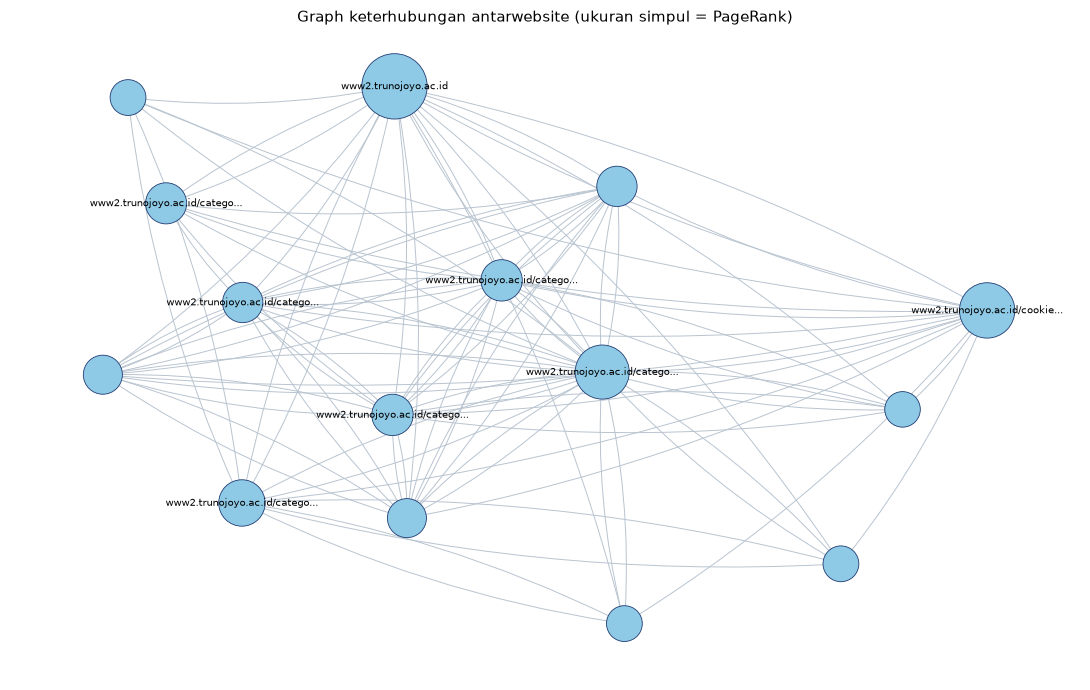

In [15]:
import matplotlib.pyplot as plt

from app.graph_analysis import gambar_graph

fig = gambar_graph(G_uji, tabel_uji, maks_label=8)
plt.show()

Gambarnya keliatan kayak bintang: satu simpul besar di tengah, simpul kecil di pinggir. Yang besar itu homepage, yang kecil halaman-halaman yang jarang di-link.

Buat 15 halaman gambarnya masih kebaca. Kalau simpulnya udah ratusan, spring layout mulai lambat dan gambarnya jadi kusut, makanya di aplikasi dipakai graph interaktif, dan buat skala besar hasilnya dibuka di Gephi.

## 4. Graph interaktif

Lokasi kode: `aplikasi-crawler-pagerank/app/graph_interaktif.py`, baris 43-153.

In [ ]:
def html_graph(
    graph: nx.DiGraph,
    tabel: pd.DataFrame,
    tinggi: int = 620,
    fisika: bool = False,
    label_semua: bool = False,
) -> str:
    """Bikin HTML graph interaktif: scroll buat zoom, geser buat pan, hover buat detail.

    Posisi simpul dihitung dulu pakai spring layout, jadi pas dibuka graphnya
    langsung rapi tanpa perlu nunggu animasi fisika.
    """
    if graph.number_of_nodes() == 0:
        return ""

    net = Network(
        height=f"{tinggi}px",
        width="100%",
        directed=True,
        bgcolor="#ffffff",
        font_color="#243b53",
        cdn_resources="in_line",  # JS-nya ikut di dalam HTML, gak butuh internet
    )

    posisi = nx.spring_layout(graph, seed=42, k=0.9, iterations=120)
    skor = dict(zip(tabel["url"], tabel["pagerank"]))
    maks = max(skor.values()) if skor else 0.0
    info = tabel.set_index("url")

    batas_label = graph.number_of_nodes() if label_semua else min(15, graph.number_of_nodes())
    url_berlabel = set(tabel.head(batas_label)["url"])

    for url in graph.nodes:
        nilai = skor.get(url, 0.0)
        baris = info.loc[url]
        net.add_node(
            url,
            label=label_pendek(url) if url in url_berlabel else "",
            title=_tooltip(url, baris),
            x=float(posisi[url][0]) * 1000,
            y=float(posisi[url][1]) * 650,
            size=10 + 44 * (0.0 if maks <= 0 else (nilai / maks) ** 0.5),
            color={
                "background": _warna_skor(nilai, maks),
                "border": "#13355e",
                "highlight": {"background": "#e76f51", "border": "#7f2b17"},
            },
        )

    for sumber, tujuan in graph.edges:
        net.add_edge(
            sumber,
            tujuan,
            arrows="to",
            title=f"{label_pendek(sumber, 40)} -> {label_pendek(tujuan, 40)}",
        )

    opsi = {
        "autoResize": True,
        "interaction": {
            "hover": True,
            "tooltipDelay": 90,
            "hideEdgesOnDrag": True,
            "navigationButtons": False,
            "keyboard": {"enabled": False},
            "multiselect": True,
            "dragNodes": True,
            "dragView": True,
            "zoomView": True,
        },
        "nodes": {
            "shape": "dot",
            "borderWidth": 1,
            "borderWidthSelected": 2,
            "font": {"size": 12, "face": "Segoe UI, Arial", "color": "#243b53"},
        },
        "edges": {
            "arrows": {"to": {"enabled": True, "scaleFactor": 0.45}},
            "color": {
                "color": "rgba(120,144,170,0.5)",
                "highlight": "#e76f51",
                "hover": "#5c7fa3",
            },
            "width": 0.7,
            "smooth": False,
            "selectionWidth": 1.2,
        },
        "physics": {
            "enabled": fisika,
            "barnesHut": {
                "gravitationalConstant": -8000,
                "centralGravity": 0.6,
                "springLength": 130,
                "springConstant": 0.03,
                "damping": 0.4,
                "avoidOverlap": 0.2,
            },
            "stabilization": {"enabled": True, "iterations": 150, "fit": True},
        },
        "layout": {"improvedLayout": False},
    }
    net.set_options(json.dumps(opsi))

    hasil = net.generate_html()
    # tanpa fisika, vis kadang gak otomatis muat semua simpul di layar
    sisipan = (
        "<script>"
        "if (window.network) { network.fit({ animation: false }); }"
        "</script>"
    )
    return hasil.replace("</body>", sisipan + "</body>")

Penjelasan:

`html_graph` bikin objek `Network` dari pyvis, yang di belakangnya pakai vis-network. `cdn_resources="in_line"` bikin JS-nya ikut ditanam di HTML, jadi file hasilnya bisa dibuka tanpa internet.

Posisi simpul dihitung dulu pakai spring layout, terus diskalakan ke koordinat canvas. Ukuran simpul ngikutin akar dari rasio PageRank, warnanya juga makin gelap kalau skornya makin besar. Tooltip tiap simpul diisi judul, URL, skor, dan in/out-degree.

Opsi interaksinya nyalain hover, drag node, drag view, dan zoom. Fisika default mati biar graph langsung rapi tanpa goyang. Di akhir, HTML-nya disisipi script `network.fit()` biar semua simpul langsung masuk layar, karna kalau fisika mati vis kadang gak otomatis muat semuanya.

In [17]:
from app.graph_interaktif import html_graph

grafik = html_graph(G_uji, tabel_uji, tinggi=640)
path_grafik = APP / "output" / "demo_graph_interaktif.html"
path_grafik.write_text(grafik, encoding="utf-8")

print("Panjang HTML    :", f"{len(grafik):,}", "karakter")
print("Ukuran file     :", f"{path_grafik.stat().st_size / 1024:,.1f}", "KB")
print("Lokasi file     :", path_grafik)
print("Ada vis.Network :", "new vis.Network" in grafik)
print("Ada network.fit :", "network.fit" in grafik)
print("Jumlah simpul   :", grafik.count('"id": "'))
print("Jumlah busur    :", grafik.count('"from":'))

Panjang HTML    : 735,068 karakter
Ukuran file     : 719.2 KB
Lokasi file     : D:\Kuliah\Semester 7\Pencarian & Penambangan Web\Webmining\aplikasi-crawler-pagerank\output\demo_graph_interaktif.html
Ada vis.Network : True
Ada network.fit : True
Jumlah simpul   : 15
Jumlah busur    : 98


Panjang HTML-nya 735 ribu karakter dan filenya 719 KB buat 15 simpul dan 98 busur. Ukuran segitu wajar karna JS vis-network ikut ditanam di dalam file.

Penanda `new vis.Network` dan `network.fit` memastikan yang dihasilkan memang graph interaktif, bukan HTML kosong. File `demo_graph_interaktif.html` di folder `output` bisa dibuka di browser buat ngecek langsung: scroll buat zoom, tarik latar buat geser, dan hover simpul buat lihat detailnya.

Yang gak bisa kubuktikan lewat notebook itu rasanya nge-drag, karna output notebook cuma teks dan gambar. Tapi di aplikasi Streamlit, HTML yang sama ditampilin lewat `st.iframe`, dan udah kucoba jalan tanpa exception.

## 5. Antarmuka Streamlit

Lokasi kode: `aplikasi-crawler-pagerank/app/streamlit_app.py`, baris 30-54.

In [ ]:
with st.sidebar:
    st.header("Pengaturan Crawling")
    with st.form("form_crawl"):
        start_url = st.text_input("URL awal", value="https://trunojoyo.ac.id")
        max_pages = st.slider("Maksimal halaman", 5, 300, 25, 5)
        max_depth = st.slider("Kedalaman crawl", 1, 3, 2)
        same_site = st.checkbox("Cuma ikuti domain yang sama", value=True)
        abaikan_navigasi = st.checkbox(
            "Abaikan menu header/footer",
            value=True,
            help=(
                "Menu navigasi muncul di semua halaman, jadi kalau ikut dihitung "
                "semua halaman saling terhubung ke halaman menu yang sama dan "
                "skor PageRank-nya jadi seri."
            ),
        )
        delay = st.slider("Jeda antar request (detik)", 0.0, 1.5, 0.2, 0.1)
        alpha = st.slider("Faktor damping alpha", 0.50, 0.95, 0.85, 0.05)
        mulai = st.form_submit_button("Mulai Crawling", type="primary", width="stretch")

    st.divider()
    st.caption(
        "Buat skala besar (sampai ratusan ribu node), jalanin lewat terminal: "
        "python run_crawl.py --max-pages 100000"
    )

Penjelasan:

Sidebar isinya form parameter crawl: URL awal, batas halaman, kedalaman, domain, opsi abaikan navigasi, jeda, dan alpha. Semuanya dibungkus `st.form` biar Streamlit gak rerun tiap kali satu slider digeser. Tombol `Mulai Crawling` yang ngirim semuanya sekaligus.

Slider halaman dibatasi 5 sampai 300. Batas ini bukan karena PageRank-nya berat, tapi karena gambar graph dan browser yang mulai kewalahan di atas itu. Buat crawl lebih besar, jalurnya lewat terminal.

Hasil crawl disimpan di `st.session_state`, jadi pas Streamlit rerun (misal user buka tab lain), hasilnya gak hilang dan gak crawl ulang. Tampilannya dibagi lima tab: ranking PageRank, graph interaktif, matriks adjacency, unduh data, dan catatan halaman gagal.

In [19]:
from pathlib import Path

from streamlit.testing.v1 import AppTest

at = AppTest.from_file(str(APP / "app" / "streamlit_app.py"), default_timeout=120)
at.run()
print("Run pertama (belum crawl), exception:", len(at.exception))

at.slider[0].set_value(8)
at.slider[2].set_value(0.0)
at.button[0].click()
at.run(timeout=300)

print("Setelah klik Crawling, exception   :", len(at.exception))
for error in at.exception:
    print("  ", error.value)

print()
print("Metric:")
for metrik in at.metric:
    print(f"  {metrik.label:22s}: {metrik.value}")
print()
print("Jumlah tab        :", len(at.tabs))
print("Label tab         :", [tab.label for tab in at.tabs])
print("Baris tabel ranking:", len(at.dataframe[0].value))
print("Tombol unduh      :", [tombol.label for tombol in at.get("download_button")])
print("Iframe graph      :", f"{len(at.get('iframe')[0].proto.srcdoc):,}", "karakter")

2026-11-18 12:02:45.128 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


Run pertama (belum crawl), exception: 0


Setelah klik Crawling, exception   : 0

Metric:
  Halaman               : 8
  Busur (link)          : 31
  Density               : 0.5536
  Rata-rata out-degree  : 3.88
  Waktu crawl           : 2.3 s

Jumlah tab        : 5
Label tab         : ['Ranking PageRank', 'Graph', 'Matriks Adjacency', 'Unduh Data', 'Catatan']
Baris tabel ranking: 8
Tombol unduh      : ['Unduh graph interaktif (HTML)', 'Unduh ranking PageRank (CSV)', 'Unduh daftar busur (CSV)']
Iframe graph      : 712,075 karakter


AppTest ngejalanin script Streamlit tanpa browser. Run pertama nunjukin halaman awal cuma nampilin info, belum ada hasil. Setelah slider dikecilin ke 8 halaman dan delay dimatikan, tombol diklik, crawl beneran jalan, dan hasilnya muncul.

Nol exception di dua run itu bukti alurnya gak ada yang crash. Metric, jumlah tab, baris tabel, dan tombol unduh nunjukin komponennya kebentuk semua. Iframe yang panjangnya ratusan ribu karakter itu graph interaktif yang tadi dibikin.

## 6. Mode terminal

Lokasi kode: `aplikasi-crawler-pagerank/run_crawl.py`, baris 14-88.

In [ ]:
def main() -> None:
    parser = argparse.ArgumentParser(
        description="Crawl website lalu hitung PageRank tiap halaman."
    )
    parser.add_argument("--start", default="https://trunojoyo.ac.id", help="URL awal")
    parser.add_argument("--max-pages", type=int, default=100, help="batas halaman")
    parser.add_argument("--max-depth", type=int, default=2, help="kedalaman crawl")
    parser.add_argument("--delay", type=float, default=0.2, help="jeda antar request")
    parser.add_argument("--alpha", type=float, default=0.85, help="faktor damping")
    parser.add_argument(
        "--semua-domain",
        action="store_true",
        help="ikut tautan ke domain lain juga (default cuma domain yang sama)",
    )
    parser.add_argument(
        "--abaikan-navigasi",
        action="store_true",
        help="buang tautan menu di header, nav, footer, dan sidebar",
    )
    parser.add_argument("--out", default="output", help="folder hasil")
    args = parser.parse_args()

    def lapor(jumlah: int, url: str) -> None:
        if jumlah % 10 == 0 or jumlah <= 3:
            print(f"[{jumlah}] {url}", flush=True)

    hasil = crawl(
        args.start,
        max_pages=args.max_pages,
        max_depth=args.max_depth,
        same_site_only=not args.semua_domain,
        delay=args.delay,
        abaikan_navigasi=args.abaikan_navigasi,
        on_progress=lapor,
    )

    graph = bangun_graph(hasil)
    tabel = peringkat_pagerank(graph, alpha=args.alpha)
    stat = statistik_graph(graph)

    folder = Path(args.out)
    folder.mkdir(parents=True, exist_ok=True)
    cap = datetime.now().strftime("%Y%m%d_%H%M%S")

    path_rank = folder / f"pagerank_{cap}.csv"
    path_busur = folder / f"busur_{cap}.csv"
    path_graph = folder / f"graph_{cap}.graphml"

    tabel.to_csv(path_rank, index=False)
    busur = pd.DataFrame(
        [(a, b) for a, b in graph.edges], columns=["sumber", "tujuan"]
    )
    busur.to_csv(path_busur, index=False)
    nx.write_graphml(graph, path_graph)

    print()
    print("===== RINGKASAN =====")
    print("Halaman        :", stat["simpul"])
    print("Busur          :", stat["busur"])
    print("Density        :", round(stat["density"], 4))
    print("Rata2 out-deg  :", round(stat["rata2_out"], 2))
    print("Waktu crawl    :", round(hasil.duration, 1), "detik")
    print("Gagal diambil  :", len(hasil.errors), "halaman")
    print()
    print("===== TOP 10 PAGERANK =====")
    for _, baris in tabel.head(10).iterrows():
        print(
            f"{baris['peringkat']:2d}. {baris['pagerank']:.6f}  "
            f"in={baris['in_degree']:3d} out={baris['out_degree']:3d}  {baris['url']}"
        )
    print()
    print("Hasil disimpan di:")
    print(" ", path_rank)
    print(" ", path_busur)
    print(" ", path_graph)

Penjelasan:

Versi terminal nerima parameter yang sama lewat argparse. Bedanya, gak ada batas 300 dan hasilnya disimpan ke disk: CSV ranking, CSV busur, dan GraphML.

GraphML itu format graph standar, bisa dibuka di Gephi atau dibaca lagi pakai networkx. Jadi buat target 100 ribu node, crawl-nya jalan di terminal, analisis dan visualisasinya dilakukan terpisah.

In [21]:
import subprocess
import sys
import tempfile
from pathlib import Path

folder_uji = Path(tempfile.mkdtemp(prefix="crawl_materi9_"))
perintah = [
    sys.executable,
    "run_crawl.py",
    "--max-pages", "12",
    "--max-depth", "2",
    "--delay", "0.05",
    "--abaikan-navigasi",
    "--out", str(folder_uji),
]

proses = subprocess.run(
    perintah,
    cwd=APP,
    capture_output=True,
    text=True,
    encoding="utf-8",
    errors="replace",
    timeout=300,
)

print("Return code:", proses.returncode)
print()
print(proses.stdout[proses.stdout.find("===== RINGKASAN"):].rstrip())
print()
print("File hasil:")
for path in sorted(folder_uji.iterdir()):
    print(f"  {path.name:30s} {path.stat().st_size / 1024:8.1f} KB")

Return code: 0

===== RINGKASAN =====
Halaman        : 12
Busur          : 60
Density        : 0.4545
Rata2 out-deg  : 5.0
Waktu crawl    : 3.0 detik
Gagal diambil  : 1 halaman

===== TOP 10 PAGERANK =====
 1. 0.233839  in= 11 out=  4  https://www2.trunojoyo.ac.id/
 2. 0.153260  in= 11 out=  1  https://www2.trunojoyo.ac.id/cookie-policy/
 3. 0.141253  in= 10 out= 10  https://www2.trunojoyo.ac.id/category/headlines/
 4. 0.098738  in=  5 out=  6  https://www2.trunojoyo.ac.id/category/informasi/
 5. 0.062191  in=  1 out=  5  https://www2.trunojoyo.ac.id/category/kegiatan/
 6. 0.056970  in=  5 out=  6  https://www2.trunojoyo.ac.id/category/berita/
 7. 0.056970  in=  5 out=  6  https://www2.trunojoyo.ac.id/category/pendidikan/
 8. 0.040648  in=  3 out=  5  https://www2.trunojoyo.ac.id/dwp-utm-gelar-dwp-mengajar-dalam-rangka-hut-ke-27-wujudkan-perempuan-berkarakter-berdaya-dan-inspiratif-menuju-indonesia-emas-2045/
 9. 0.040648  in=  3 out=  5  https://www2.trunojoyo.ac.id/halaqoh-dakwah-se-

Return code 0 berarti script selesai tanpa error. Bagian RINGKASAN nyatet 12 halaman, 60 busur, density 0.4545, dan 1 halaman gagal. Top 10 di bawahnya nunjukin urutan PageRank-nya, sama kayak yang ditampilin di tab ranking.

Daftar file nunjukin tiga artefak yang dijanjikan memang kebentuk. Ukuran CSV ranking ngikut jumlah halaman, CSV busur ngikut jumlah tautan, dan GraphML paling besar karna nyimpen atribut simpul juga. Folder uji cobanya ada di direktori sementara sistem, jadi gak numpuk di repo.

## 7. Kesimpulan

Aplikasi ini nyambungin teori di materi 7 dan 8 jadi satu alur: crawl, bentuk graph, hitung PageRank, terus tampilkan.

Pembuktian di notebook nunjukin normalisasi URL beneran nyatuin bentuk URL yang beda, ekstraksi tautan beneran ngurang setelah menu dibuang, crawl berhenti sesuai antrean dan kedalaman, graph cuma nerima busur yang kedua ujungnya ada, dan total PageRank mendekati 1.

Di sisi tampilan, AppTest nunjukin aplikasi jalan tanpa exception, lima tab kebentuk, tabel ranking berisi seluruh halaman, dan graph interaktif ke-render sebagai iframe. Versi terminal juga terbukti menghasilkan CSV dan GraphML.

## 8. Catatan deploy

Deploy-nya pakai Streamlit Community Cloud. Aplikasinya dipisah ke repo sendiri, `dummymhs/aplikasi-crawler-pagerank`, dengan branch `main` dan main file `app/streamlit_app.py`.

Dipisah begini karna Streamlit Cloud nyari `requirements.txt` di root repo. Repo catatan ini root-nya dipakai buat Jupyter Book, jadi kalau aplikasinya ikut di situ file requirements-nya jadi numpuk sama keperluan book. Di repo aplikasi, `requirements.txt` udah ada di root, jadi gak perlu setting tambahan.

Langkah deploy-nya: buka share.streamlit.io, login pakai GitHub, pilih repo `dummymhs/aplikasi-crawler-pagerank`, branch `main`, main file `app/streamlit_app.py`, terus Deploy. Gak ada secret yang perlu diisi, aplikasinya cuma butuh akses internet buat crawling.

Setelah deploy, link aplikasinya ditaruh di bagian paling atas catatan ini.